# 02 · Acquisition: `acq` and `pe`

The PIC32AK samples the RX chain at 25 Msps (40 ns per sample) and sends 4095 samples to the RP, which prints them
as one number per line after a `# acq …` header. `acq` captures without firing the pulser. `pe` (pulse-echo) fires
the pulser exactly when the capture starts. A transducer on the board gives echoes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "library"))   # the minus package (or: pip install -e python/library)
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")   # harmless on mixed matplotlib installs
import numpy as np
import matplotlib.pyplot as plt
from minus import Minus, MinusError
import minus
print("library", minus.__version__, "written for firmware", minus.FIRMWARE)

library 1.1.1 written for firmware {'rp': {'name': 'minus-rp2354', 'version': '1.1.1'}, 'pic': {'name': 'minus-pic32', 'version': '1.1.0'}, 'proto': 10}


In [2]:
dev = Minus()
dev.version().version, dev.pic_ident().version

('1.1.1', '1.1.0')

## 1. `acq`: a capture without a pulse (noise floor)

`acq(div, samc, in_, navg)`: `div` = trigger period in 5 ns counts (4 → 25 Msps), `samc` = ADC sampling time,
`in_` = which node (25 = the filtered RX output, see `minus.INPUTS`), `navg` = conversions summed per sample.
The PIC remembers these settings between calls.

In [3]:
minus.INPUTS

{25: 'AD2AN9: OA2 output after the anti-alias filter (default)',
 17: 'AD2AN1: OA2 output before the filter',
 0: 'AD1AN0: OA1 output',
 1: 'AD1AN1: OA1 input = LNA output'}

In [4]:
a = dev.acq(4, 0, 25, 1)
dev.last.show()

>>> acq 4 0 25 1
<<< # acq n=4095 fill=164.6us fs=24.87Msps rp_fill=161us (RDY window timed by the RP crystal) trigger div 4; in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3); navg=1 (12-bit unsigned)
<<< 2032
<<< 2030
<<< 2036
<<< 2040
<<< 2038
<<< ... (4084 more lines) ...
<<< 2031
<<< 2034
<<< 2030
<<< 2033
<<< 2028
<<< 2033
    (4096 lines, 872 ms)


The header line says how long the capture window took, measured by the PIC (`fill`) and independently by the RP
from the RDY line (`rp_fill`), and the resulting sample rate. The `Capture` object holds the samples as a numpy array:

In [5]:
print(a.n, "samples,", a.fs_msps, "Msps,", round(a.dt_ns, 2), "ns/sample, window", a.fill_us, "us")
print("mean %.1f LSB, std %.2f LSB" % (a.samples.mean(), a.samples.std()))
a.samples[:10]

4095 samples, 24.87 Msps, 40.2 ns/sample, window 164.6 us
mean 2032.8 LSB, std 6.60 LSB


array([2032, 2030, 2036, 2040, 2038, 2035, 2037, 2033, 2034, 2027],
      dtype=uint16)

## 2. `gain`: RX gain

Both op-amp stages share one analog mux: `leg` 0..3 picks Rf = 2.2k/4.7k/6.8k/10k (×3.2/×5.7/×7.8/×11 per
stage, before the LNA). `u1`/`u2` = 1 bypasses that stage (×1).

In [6]:
g = dev.gain(2, 0, 0)
dev.last.show()
g

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 58 ms)


Gain(leg=2, rf_ohm=6800.0, oa1=7.8, oa1_unity=False, oa2=7.8, oa2_unity=False, total=60.8, total_db=35.7)

## 3. `pe`: one pulse-echo A-line

`pe(hi, lo, in_, dead)`: the pulser drives +5 V for `hi` ns, both FETs off for `dead` ns, then GND for `lo` ns.
Defaults 200 / 500 / 27. The reply is the same as `acq` plus a final `# pulse fired, k shot(s)` line. Sometimes the
ADC locks to a slower pattern, so `pe` re-shoots until the sample clock is uniform; `shots` says how many tries it took.

In [7]:
e = dev.pe(200, 500, 25, 27)
dev.last.show()
print("fired:", e.pulse_fired, "| shots:", e.shots)

>>> pe 200 500 25 27
<<< # acq n=4095 fill=164.6us fs=24.87Msps rp_fill=164us (RDY window timed by the RP crystal) pulse-echo: pulse on RDY rise (+5V 200 / off 27 / GND 500 ns), in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3), 40 ns/sample; gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA); try 3
<<< 2832
<<< 3730
<<< 4008
<<< 4042
<<< 4051
<<< ... (4085 more lines) ...
<<< 2040
<<< 2033
<<< 2034
<<< 2034
<<< 2020
<<< # pulse fired, 3 shot(s)
    (4097 lines, 984 ms)
fired: True | shots: 3


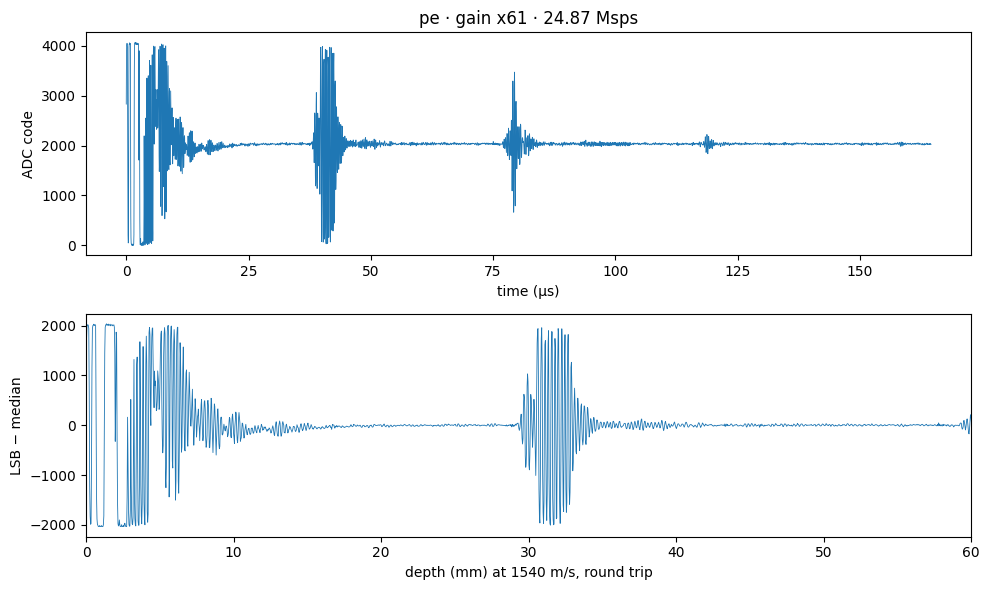

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(e.t_us, e.samples, lw=0.6)
ax[0].set(xlabel="time (µs)", ylabel="ADC code", title=f"pe · gain x{g.total:.0f} · {e.fs_msps} Msps")
ax[1].plot(e.depth_mm(), e.samples.astype(float) - np.median(e.samples), lw=0.6)
ax[1].set(xlabel="depth (mm) at 1540 m/s, round trip", ylabel="LSB − median", xlim=(0, 60))
plt.tight_layout()

## 4. Gain sweep

Same pulse, all four legs. The main bang (the transmit pulse leaking into RX) clips at high gain; the echoes grow.

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 58 ms)


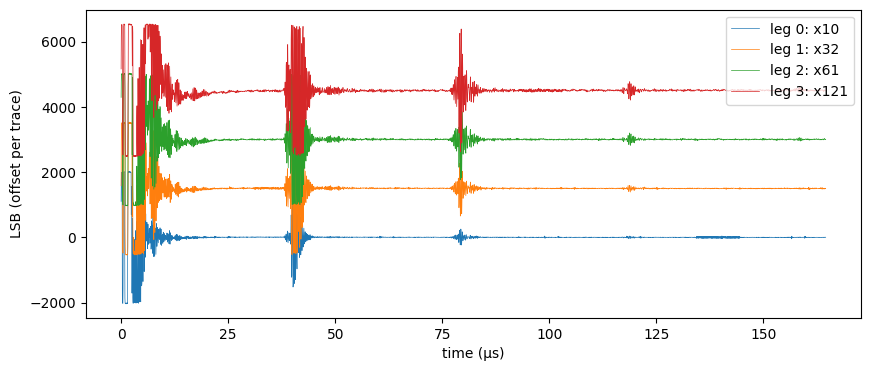

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for leg in range(4):
    gl = dev.gain(leg, 0, 0)
    c = dev.pe()
    ax.plot(c.t_us, c.samples.astype(float) - np.median(c.samples) + 1500 * leg, lw=0.5, label=f"leg {leg}: x{gl.total:.0f}")
ax.set(xlabel="time (µs)", ylabel="LSB (offset per trace)"); ax.legend(loc="upper right")
dev.gain(2, 0, 0); dev.last.show()

## 5. `pc`: pattern correction

The ADC shows a small fixed pattern with a period of 4 samples. The PIC subtracts it (on at boot). `pc` reports
the state and the per-phase offsets it removed from the last capture. Compare the noise with it on and off:

In [10]:
for on in (False, True):
    s = dev.pattern_correction(on); dev.last.show()
    c = dev.acq(4, 0, 25, 1)
    x = c.samples.astype(float)
    phase_means = [x[k::4].mean() - x.mean() for k in range(4)]
    print(f"pc {'on ' if on else 'off'}: std {x.std():.2f} LSB, period-4 means {np.round(phase_means, 2)}")
print(dev.pattern_correction())

>>> pc 0
<<< pattern correction off; last capture offsets (LSB, phase 0..3): +11.81 +4.38 -20.81 +4.62
    (1 lines, 54 ms)


pc off: std 14.81 LSB, period-4 means [-18.03   3.08   9.12   5.84]
>>> pc 1
<<< pattern correction ON; last capture offsets (LSB, phase 0..3): +11.81 +4.38 -20.81 +4.62
    (1 lines, 53 ms)


pc on : std 10.03 LSB, period-4 means [ 0.13  0.05 -0.   -0.17]
PatternCorrection(on=True, offsets_lsb=(-17.88, 3.06, 9.0, 5.81))


## 6. Averaging several shots

The sample comb's phase relative to the pulse changes from shot to shot, by up to one sample (40 ns; datasheet E3).
Align shots on a strong echo before averaging them, otherwise the echoes smear. Here: cross-correlate each shot
with the first one around the first echo, apply the sub-sample shift in the Fourier domain, then average.

shot lags vs shot 0 (samples): [ 0.   -0.4  -0.02 -0.08 -0.02 -0.58  0.22 -0.31]


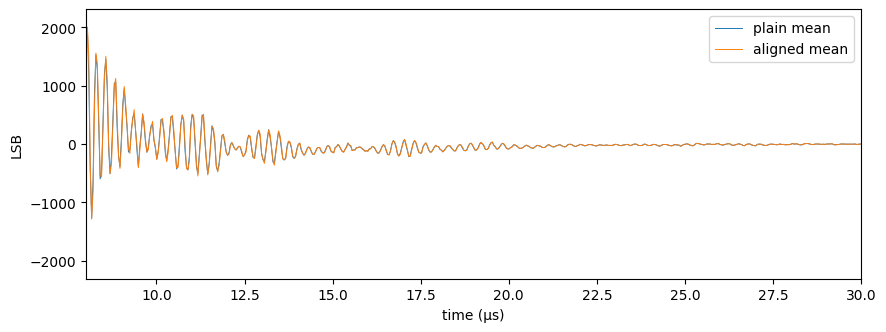

In [11]:
shots = [dev.pe().samples.astype(float) for _ in range(8)]
X = np.array([s - np.median(s) for s in shots])
win = slice(250, 1500)                                     # skip the main bang, keep the first echoes
ref = X[0, win]
def lag_of(x):
    cc = np.correlate(x[win], ref, "full"); k = cc.argmax()
    y0, y1, y2 = cc[k - 1:k + 2]
    return k - (len(ref) - 1) + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
lags = np.array([lag_of(x) for x in X])
f = np.fft.rfftfreq(X.shape[1])
aligned = np.array([np.fft.irfft(np.fft.rfft(x) * np.exp(2j * np.pi * f * l), X.shape[1]) for x, l in zip(X, lags)])
print("shot lags vs shot 0 (samples):", np.round(lags, 2))
t = np.arange(X.shape[1]) * e.dt_ns / 1000
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, X.mean(0), lw=0.7, label="plain mean")
ax.plot(t, aligned.mean(0), lw=0.7, label="aligned mean")
ax.set(xlim=(8, 30), xlabel="time (µs)", ylabel="LSB"); ax.legend()

In [12]:
dev.gain(0, 0, 0)
dev.close()